<a href="https://colab.research.google.com/github/Akash14-09/Machine_Learning/blob/main/Le_NET5_Architecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow
from tensorflow import keras
from keras.layers import Dense , Conv2D , Flatten , AveragePooling2D
from keras import Sequential
from keras.datasets import mnist

In [2]:
(X_train , y_train) , (X_test , y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
model = Sequential()

#first conv and pooling layer
model.add(Conv2D(6,kernel_size=(5,5) , strides=(1,1) , padding='valid' , activation='tanh' , input_shape=(28,28,1)))
model.add(AveragePooling2D(pool_size=(2,2) , strides=(2,2) , padding='valid'))

#second conv and pooling layer
model.add(Conv2D(16,kernel_size=(5,5) , strides=(1,1) , padding='valid' , activation='tanh'))
model.add(AveragePooling2D(pool_size=(2,2) , strides=(2,2) , padding='valid'))

#flattening the data
model.add(Flatten())


#fully connected layer
model.add(Dense(129 , activation='tanh'))
model.add(Dense(84 , activation='tanh'))

#softmax layer
model.add(Dense(10 , activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
# 1. Preprocess the data (normalize pixel values and reshape to (28, 28, 1))
X_train_processed = X_train.astype("float32") / 255.0
X_test_processed = X_test.astype("float32") / 255.0

import numpy as np
X_train_processed = np.expand_dims(X_train_processed, -1)
X_test_processed = np.expand_dims(X_test_processed, -1)

# 2. Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Train the model
history = model.fit(
    X_train_processed,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_processed, y_test)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 25s 25ms/step - accuracy: 0.9173 - loss: 0.2783 - val_accuracy: 0.9622 - val_loss: 0.1233
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - accuracy: 0.9696 - loss: 0.1008 - val_accuracy: 0.9757 - val_loss: 0.0733
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 24ms/step - accuracy: 0.9793 - loss: 0.0676 - val_accuracy: 0.9790 - val_loss: 0.0654
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.9838 - loss: 0.0527 - val_accuracy: 0.9822 - val_loss: 0.0545
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 25ms/step - accuracy: 0.9867 - loss: 0.0424 - val_accuracy: 0.9828 - val_loss: 0.0556
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 25ms/step - accuracy: 0.9891 - loss: 0.0351 - val_accuracy: 0.9836 - val_loss: 0.0518
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - accuracy: 0.9903 - loss: 0.0297 - val_accuracy: 0.9823 - val_loss: 0.0551
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 25ms/step - accuracy: 0.9922 - loss: 0.0246 - 

####You can see as above the accuracy is more than 99 becuase CNN is best algorithm over image classification dataset , it is perfroming much better than ANN and other algorithms.

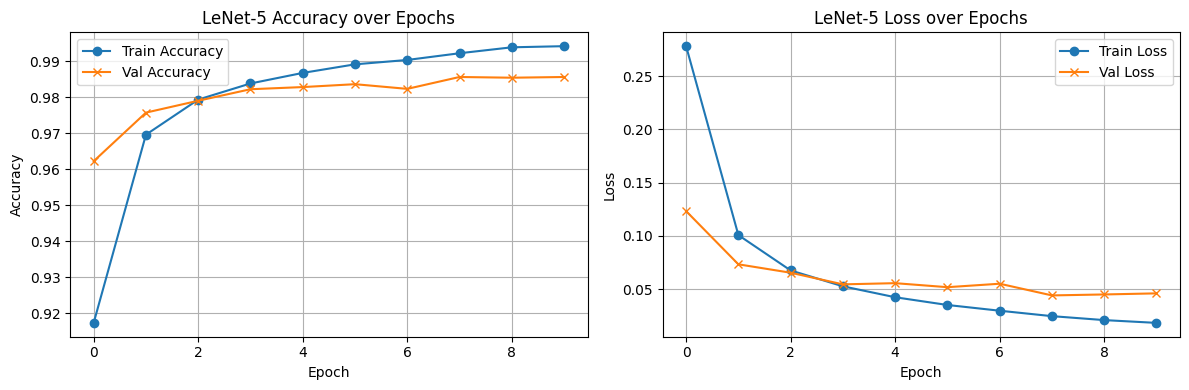

In [5]:
import matplotlib.pyplot as plt

# Plot Training & Validation Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='x')
plt.title('LeNet-5 Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Training & Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='x')
plt.title('LeNet-5 Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()